# Proyecto Final: Minería de Datos aplicada a Spotify
**Materia:** Minería de Datos | **Grupo:** 032 | **Dataset:** `dataset.csv` (Spotify Tracks Dataset, 114,000 registros y 21 columnas)

En este notebook se desarrollan los **4 problemas** planteados para el caso de estudio de Spotify:

1. **Segmentación de canciones** por sus características de audio (K-Means con PCA).
2. **Predicción de la popularidad** de una canción (Random Forest y Gradient Boosting).
3. **Clasificación del género musical** usando solo características acústicas (Random Forest y SVM).
4. **Reglas de asociación** entre características de audio y popularidad alta (Apriori).

Con esto se cubren **dos tipos de análisis**: descriptivo / no supervisado (problemas 1 y 4) y predictivo / supervisado (problemas 2 y 3).

## Importar las librerias

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'figure.dpi': 100})

## Cargar los datos

In [2]:
dataset = pd.read_csv('dataset.csv')

In [3]:
dataset.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
dataset.shape

(114000, 21)

## Calidad de los datos
Se revisa el tipo de dato de cada columna, los valores nulos, los valores únicos y los duplicados.

In [5]:
dataset = dataset.drop(columns='Unnamed: 0')
calidad = pd.DataFrame({'tipo': dataset.dtypes.astype(str), 'nulos': dataset.isna().sum(), 'valores_unicos': dataset.nunique()})
calidad

,tipo,nulos,valores_unicos
track_id,str,0,89741
artists,str,1,31437
album_name,str,1,46589
track_name,str,1,73608
popularity,int64,0,101
duration_ms,int64,0,50697
explicit,bool,0,2
danceability,float64,0,1174
energy,float64,0,2083
key,int64,0,12


In [6]:
dataset.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
key,114000.0,5.309,3.560,0.000,2.000,5.000,8.000,11.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
mode,114000.0,0.638,0.481,0.000,0.000,1.000,1.000,1.000
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.049,1.000


In [7]:
print('Filas duplicadas exactas:', dataset.duplicated().sum())
print('track_id repetidos:', dataset['track_id'].duplicated().sum())
print('Canciones distintas (track_id):', dataset['track_id'].nunique())
print('Generos distintos:', dataset['track_genre'].nunique())
print('Canciones por genero (min, max):', dataset['track_genre'].value_counts().min(), dataset['track_genre'].value_counts().max())
print('Tempo = 0:', (dataset['tempo'] == 0).sum(), '| time_signature = 0:', (dataset['time_signature'] == 0).sum(), '| duracion = 0:', (dataset['duration_ms'] == 0).sum())
print('Popularidad = 0:', (dataset['popularity'] == 0).sum())

Filas duplicadas exactas: 450
track_id repetidos: 24259
Canciones distintas (track_id): 89741
Generos distintos: 114
Canciones por genero (min, max): 1000 1000
Tempo = 0: 157 | time_signature = 0: 163 | duracion = 0: 1
Popularidad = 0: 16020


**Hallazgos de calidad:**
- Solo **1 fila** tiene valores nulos (artista, álbum y nombre de la canción).
- Hay **canciones repetidas**: una misma canción (`track_id`) aparece en más de un género, por eso hay más filas que canciones distintas. Esto se tiene que cuidar al separar entrenamiento y prueba.
- Hay registros con **tempo, compás o duración igual a 0**, que son mediciones inválidas de la API (no se pudo detectar el valor).
- Cada género tiene exactamente **1,000 registros**, así que los géneros están balanceados.

## Limpieza y preparación
Se eliminan la fila con nulos y las mediciones inválidas. Después se crean dos versiones de los datos:
- `dataset`: una fila por cada combinación canción-género (se usa en los análisis supervisados 2 y 3).
- `canciones`: una fila por canción distinta (se usa en la segmentación y en las reglas de asociación para no contar dos veces la misma canción).

In [8]:
dataset = dataset.dropna()
dataset = dataset[(dataset['tempo'] > 0) & (dataset['time_signature'] > 0) & (dataset['duration_ms'] > 0)].reset_index(drop=True)
dataset['explicit'] = dataset['explicit'].astype(int)
dataset['cancion'] = dataset['artists'].str.lower() + ' | ' + dataset['track_name'].str.lower()
canciones = dataset.drop_duplicates('track_id').reset_index(drop=True)
print('Registros (cancion-genero):', len(dataset))
print('Canciones distintas:', len(canciones))

Registros (cancion-genero): 113836
Canciones distintas: 89578


## Análisis exploratorio (EDA)

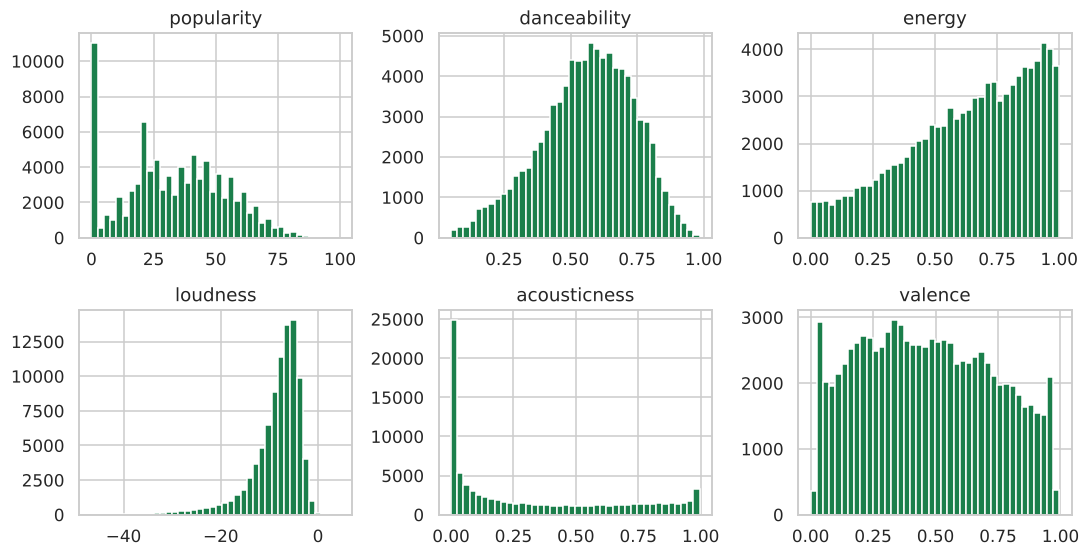

In [9]:
columnas = ['popularity', 'danceability', 'energy', 'loudness', 'acousticness', 'valence']
fig, ejes = plt.subplots(2, 3, figsize=(10, 5.2))
for eje, col in zip(ejes.ravel(), columnas):
    eje.hist(canciones[col], bins=40, color='#1B7F4B')
    eje.set_title(col)
plt.tight_layout()
plt.show()

La **popularidad** tiene muchísimas canciones con valores muy bajos (incluyendo el 0) y pocas con valores altos. `danceability` y `valence` se parecen a una campana, `energy` y `loudness` se cargan hacia valores altos y `acousticness` se carga hacia valores bajos.

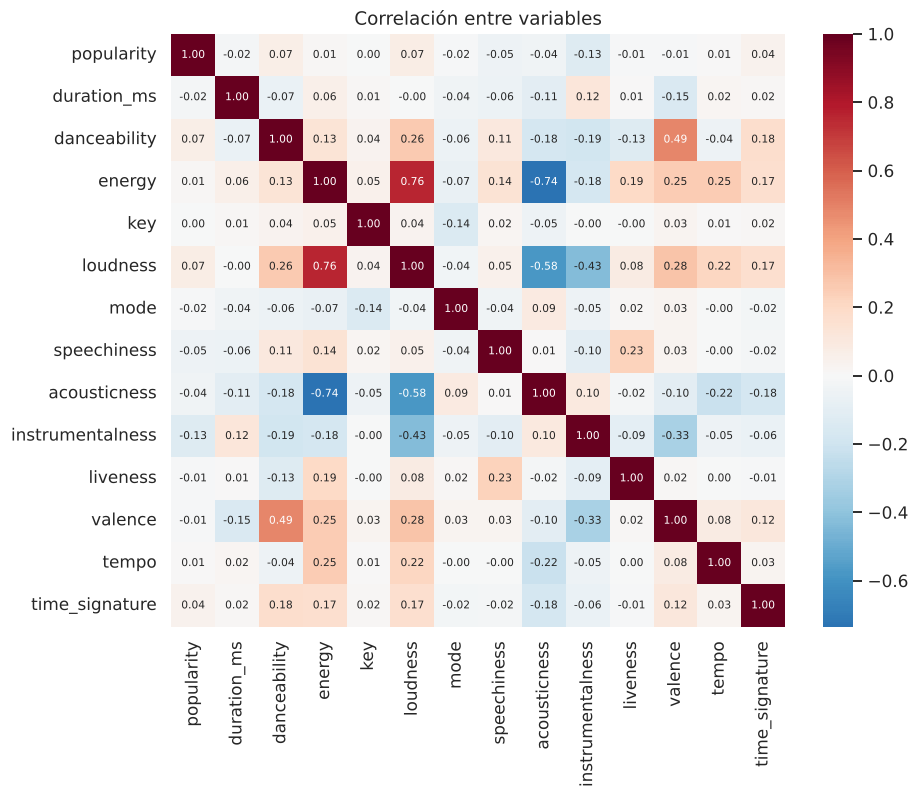

In [10]:
numericas = ['popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
plt.figure(figsize=(9, 7))
sns.heatmap(canciones[numericas].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size': 7})
plt.title('Correlación entre variables')
plt.show()

Las correlaciones de `popularity` con las demás variables son **muy débiles**: la más fuerte es con `instrumentalness` (-0.13), seguida de `loudness` (0.07) y `danceability` (0.07). Es una primera señal de que la popularidad no se explica bien solo con el sonido de la canción.

Por otro lado, `energy`, `loudness` y `acousticness` están muy relacionadas entre sí: la correlación entre `energy` y `loudness` es 0.76 y entre `energy` y `acousticness` es -0.74. Es decir, las canciones más intensas suelen ser más fuertes y menos acústicas.

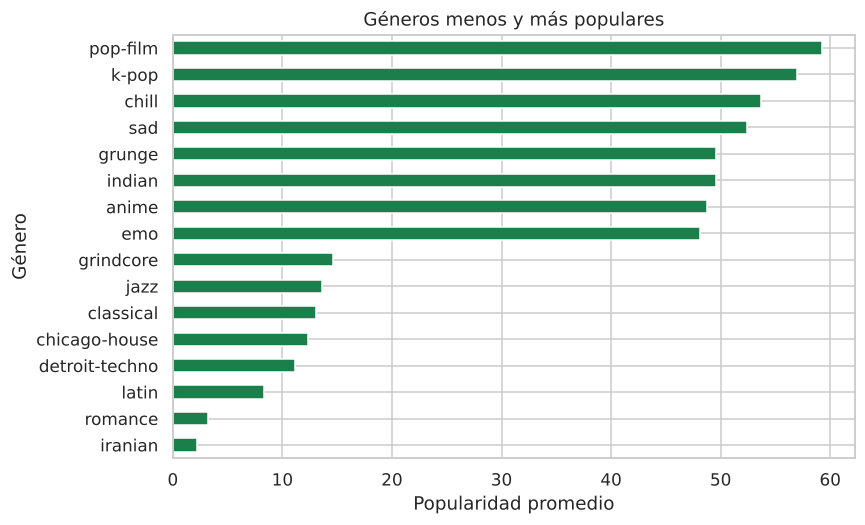

In [11]:
por_genero = dataset.groupby('track_genre')['popularity'].mean().sort_values()
extremos = pd.concat([por_genero.head(8), por_genero.tail(8)])
extremos.plot(kind='barh', figsize=(8, 5), color='#1B7F4B')
plt.xlabel('Popularidad promedio')
plt.ylabel('Género')
plt.title('Géneros menos y más populares')
plt.show()

Los géneros con menor popularidad promedio son *iranian* (2.2), *romance* (3.2) y *latin* (8.3), y los más populares son *pop-film* (59.3), *k-pop* (57.0) y *chill* (53.7). Una diferencia de 2 a casi 60 puntos entre géneros indica que el **género es una variable clave para explicar la popularidad**, y por eso se usa en el análisis 2.

# Análisis 1: Segmentación de canciones (K-Means con PCA)
**Tipo de análisis:** descriptivo / no supervisado. **Objetivo:** agrupar canciones con características acústicas parecidas para construir un sistema de recomendación basado en contenido.

Se usan 9 características de audio continuas. `key`, `mode` y `time_signature` no se usan porque son categóricas / discretas y `duration_ms` es metadato, no una característica acústica.

## Seleccionar y estandarizar las características
K-Means usa distancias, y `tempo` (60 a 200) y `loudness` (-60 a 0) están en escalas muy distintas a las demás variables (0 a 1). Por eso se **estandarizan** (igual que en la tarea de segmentación de mercado).

In [12]:
from sklearn.preprocessing import StandardScaler
caracteristicas = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
escalador = StandardScaler()
X_seg = escalador.fit_transform(canciones[caracteristicas])
X_seg.shape

(89578, 9)

## Método del codo y coeficiente de silueta
Se prueba K-Means con k de 2 a 10. Además de la WCSS (codo), se calcula el **coeficiente de silueta** (qué tan separados están los grupos; entre más cercano a 1, mejor) usando una muestra de 10,000 canciones para que sea rápido.

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
muestra = np.random.RandomState(0).choice(len(X_seg), 10000, replace=False)
wcss, silueta = [], []
for k in range(2, 11):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_seg)
    wcss.append(modelo_k.inertia_)
    silueta.append(silhouette_score(X_seg[muestra], modelo_k.labels_[muestra]))
pd.DataFrame({'k': range(2, 11), 'WCSS': np.round(wcss, 0), 'Silueta': np.round(silueta, 3)})

,k,WCSS,Silueta
0,2,632568.0,0.259
1,3,561036.0,0.168
2,4,504696.0,0.174
3,5,455847.0,0.179
4,6,414121.0,0.191
5,7,376636.0,0.197
6,8,355561.0,0.174
7,9,337114.0,0.179
8,10,323249.0,0.166


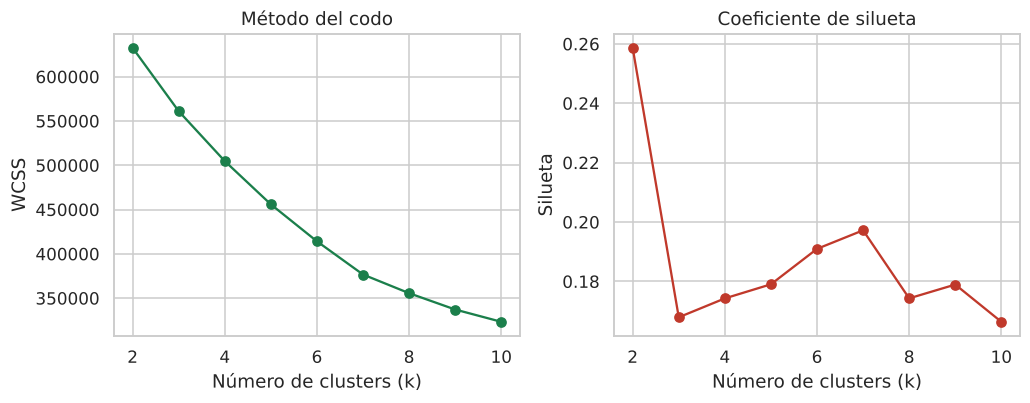

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 3.8))
ejes[0].plot(range(2, 11), wcss, marker='o', color='#1B7F4B')
ejes[0].set_title('Método del codo')
ejes[0].set_xlabel('Número de clusters (k)')
ejes[0].set_ylabel('WCSS')
ejes[1].plot(range(2, 11), silueta, marker='o', color='#C0392B')
ejes[1].set_title('Coeficiente de silueta')
ejes[1].set_xlabel('Número de clusters (k)')
ejes[1].set_ylabel('Silueta')
plt.tight_layout()
plt.show()

- La WCSS baja de forma continua al subir k y **no se ve un codo claro**.
- El coeficiente de silueta es más alto con k = 2 (0.259), pero con solo 2 grupos únicamente se separa música intensa de música suave, algo demasiado general para recomendar. Después tiene un máximo local en k = 7 (0.197) y vale 0.179 con k = 5.
- Todos los valores son bajos (menores a 0.26): los grupos no quedan completamente separados, lo cual es normal en variables de audio continuas donde los estilos se mezclan poco a poco.
- Se eligió **k = 5** porque da segmentos con una interpretación musical clara y de tamaño razonable (incluyendo un grupo de contenido hablado). Con k = 6 aparece un grupo de grabaciones en vivo (`liveness` ≈ 0.73) y con k = 7 otro de música instrumental intensa; son subdivisiones válidas, pero k = 5 resume mejor las grandes familias de sonido.

## Entrenar K-Means con el k elegido

In [15]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=0)
canciones['cluster'] = kmeans.fit_predict(X_seg)
canciones['cluster'].value_counts().sort_index()

cluster
0     1098
1    33735
2    20655
3    26824
4     7266
Name: count, dtype: int64

## Perfil de cada cluster
Promedio de cada característica por grupo (escala original) y cuántas canciones tiene cada grupo.

In [16]:
perfil = canciones.groupby('cluster')[caracteristicas].mean().round(2)
perfil['canciones'] = canciones['cluster'].value_counts().sort_index()
perfil

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,canciones
cluster,,,,,,,,,,
0,0.57,0.68,-11.08,0.83,0.73,0.01,0.67,0.45,101.76,1098
1,0.69,0.73,-6.55,0.09,0.21,0.07,0.19,0.69,120.53,33735
2,0.53,0.39,-10.48,0.06,0.67,0.06,0.19,0.40,113.59,20655
3,0.48,0.82,-5.97,0.08,0.07,0.24,0.26,0.32,136.44,26824
4,0.37,0.20,-20.54,0.05,0.82,0.79,0.16,0.19,105.87,7266


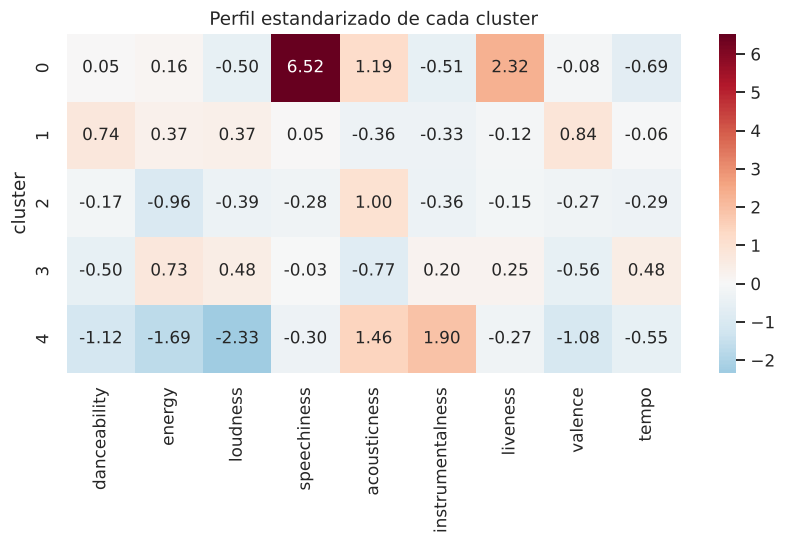

In [17]:
perfil_z = pd.DataFrame(X_seg, columns=caracteristicas).groupby(canciones['cluster']).mean()
plt.figure(figsize=(9, 4))
sns.heatmap(perfil_z, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Perfil estandarizado de cada cluster')
plt.show()

Los 5 segmentos tienen perfiles bien diferenciados (aunque el género **no** se usó para agrupar, los géneros más frecuentes de cada grupo confirman su interpretación):

| Cluster | Segmento | Canciones | Rasgos principales | Géneros más frecuentes |
|---|---|---|---|---|
| 0 | **Hablado** | 1,098 (1.2%) | `speechiness` 0.83, `liveness` 0.67 | comedy |
| 1 | **Bailable y alegre** | 33,735 (37.7%) | `danceability` 0.69, `valence` 0.69, volumen alto | salsa, dancehall, forró |
| 2 | **Suave y acústico** | 20,655 (23.1%) | `energy` 0.39, `acousticness` 0.67 | tango, honky-tonk, cantopop |
| 3 | **Intenso y oscuro** | 26,824 (29.9%) | `energy` 0.82, `valence` 0.32, `tempo` 136, `acousticness` 0.07 | grindcore, black-metal, death-metal |
| 4 | **Instrumental y ambiental** | 7,266 (8.1%) | `instrumentalness` 0.79, `loudness` -20.5, `energy` 0.20 | new-age, sleep, ambient |

## Nombrar los segmentos
Con base en el perfil se le pone un nombre a cada cluster para poder interpretarlo.

In [18]:
nombres = {0: 'Hablado', 1: 'Bailable y alegre', 2: 'Suave y acústico', 3: 'Intenso y oscuro', 4: 'Instrumental y ambiental'}
canciones['segmento'] = canciones['cluster'].map(nombres)
resumen_seg = canciones['segmento'].value_counts().to_frame('canciones')
resumen_seg['porcentaje'] = (resumen_seg['canciones'] / len(canciones) * 100).round(1)
resumen_seg

,canciones,porcentaje
segmento,,
Bailable y alegre,33735,37.7
Intenso y oscuro,26824,29.9
Suave y acústico,20655,23.1
Instrumental y ambiental,7266,8.1
Hablado,1098,1.2


## PCA para visualizar los clusters
Son 9 variables, así que no se pueden graficar directamente. Con **PCA** se reducen a 2 componentes principales que conservan la mayor parte posible de la varianza y se grafica una muestra de 15,000 canciones.

In [19]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=0)
componentes = pca.fit_transform(X_seg)
print('Varianza explicada por PC1 y PC2:', pca.explained_variance_ratio_.round(3), '| total:', pca.explained_variance_ratio_.sum().round(3))
pd.DataFrame(pca.components_.T, index=caracteristicas, columns=['PC1', 'PC2']).round(2)

Varianza explicada por PC1 y PC2: [0.319 0.16 ] | total: 0.479


,PC1,PC2
danceability,0.25,0.57
energy,0.51,-0.28
loudness,0.52,-0.08
speechiness,0.10,0.04
acousticness,-0.44,0.31
instrumentalness,-0.28,-0.32
liveness,0.09,-0.21
valence,0.30,0.53
tempo,0.19,-0.28


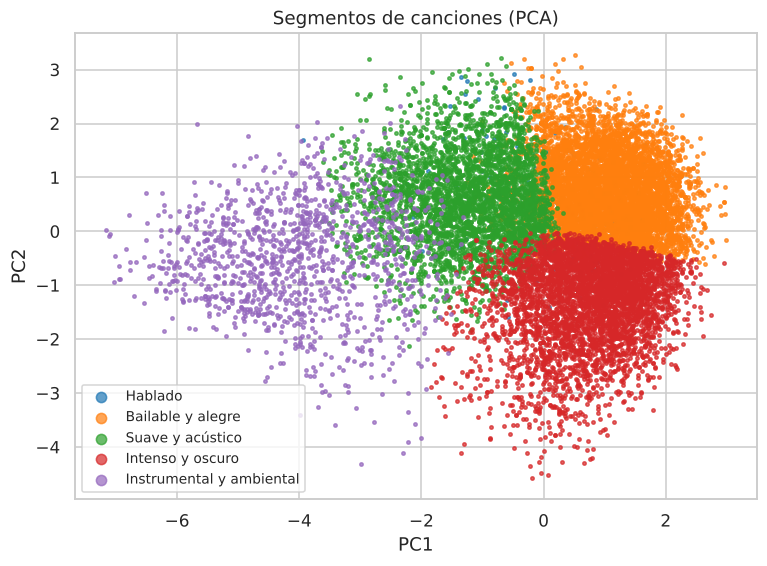

In [20]:
visual = np.random.RandomState(1).choice(len(componentes), 15000, replace=False)
plt.figure(figsize=(8, 5.5))
for k, nombre in nombres.items():
    puntos = visual[canciones['cluster'].values[visual] == k]
    plt.scatter(componentes[puntos, 0], componentes[puntos, 1], s=5, alpha=0.7, color=plt.cm.tab10(k), label=nombre)
plt.legend(markerscale=3, fontsize=9)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Segmentos de canciones (PCA)')
plt.show()

Los dos primeros componentes explican el **47.9%** de la varianza (PC1 = 31.9% y PC2 = 16.0%).
- **PC1** pesa sobre todo `loudness` (0.52) y `energy` (0.51) en un sentido y `acousticness` (-0.44) en el otro: separa la música intensa de la suave y acústica.
- **PC2** pesa `danceability` (0.57) y `valence` (0.53): separa las canciones alegres y bailables de las más serias.

El segmento *Instrumental y ambiental* queda claramente a la izquierda (PC1 bajo), mientras que *Bailable y alegre* e *Intenso y oscuro* se tocan en el lado derecho. Las regiones se traslapan, lo que coincide con la silueta baja.

## Sistema de recomendación basado en contenido
Para recomendar, se toma la canción elegida, se buscan las canciones de **su mismo segmento** y se ordenan por **similitud coseno** entre sus características estandarizadas.

In [21]:
from sklearn.metrics.pairwise import cosine_similarity
def recomendar(nombre, artista=None, n=5):
    candidatos = canciones[canciones['track_name'].str.lower() == nombre.lower()]
    if artista:
        candidatos = candidatos[candidatos['artists'].str.lower().str.contains(artista.lower())]
    posicion = candidatos.index[0]
    mismo_cluster = canciones.index[canciones['cluster'] == canciones.loc[posicion, 'cluster']]
    similitud = cosine_similarity(X_seg[[posicion]], X_seg[mismo_cluster])[0]
    orden = mismo_cluster[np.argsort(-similitud)]
    orden = [i for i in orden if canciones.loc[i, 'cancion'] != canciones.loc[posicion, 'cancion']][:n]
    return canciones.loc[orden, ['track_name', 'artists', 'track_genre', 'segmento', 'popularity']]

In [22]:
recomendar('Despacito', 'fonsi')

,track_name,artists,track_genre,segmento,popularity
57138,Despacito - Remix,Luis Fonsi;Daddy Yankee;Justin Bieber,latin,Bailable y alegre,70
57082,Despacito - Remix,Luis Fonsi;Daddy Yankee;Justin Bieber,latin,Bailable y alegre,72
57389,Despacito (Featuring Daddy Yankee),Luis Fonsi;Daddy Yankee,latin,Bailable y alegre,61
71806,Bang Bang,K'NAAN;Adam Levine,reggae,Bailable y alegre,69
76247,No lo Esperaba,Ezio Oliva;ADSO,salsa,Bailable y alegre,28


Para *Despacito* (segmento *Bailable y alegre*) las 3 primeras recomendaciones son otras versiones de la misma canción (dos remixes y una versión con Daddy Yankee, con popularidad de 61 a 72), lo cual sirve como **comprobación** de que la similitud funciona. Las siguientes (*Bang Bang* de K'NAAN y Adam Levine, *No lo Esperaba* de Ezio Oliva) son de otros géneros (reggae y salsa) pero suenan parecido, es decir, el sistema ayuda a **descubrir música de sonido similar fuera del género habitual**.

La limitación es que solo usa el audio: no toma en cuenta el idioma, la letra ni el gusto de cada usuario.

# Análisis 2: Predicción de la popularidad
**Tipo de análisis:** predictivo / supervisado (regresión). **Objetivo:** predecir el puntaje de popularidad (0 a 100) de una canción a partir de sus características de audio y metadatos.

Como `popularity` es un número continuo, es un problema de **regresión**. Se comparan un modelo base (siempre predice el promedio), una regresión lineal, **Random Forest** y **Gradient Boosting** (`HistGradientBoostingRegressor`, el equivalente en scikit-learn de XGBoost).

## Separar en entrenamiento y prueba
Como la misma canción puede aparecer en varios géneros, la separación se hace **por grupos** (`GroupShuffleSplit`): todas las apariciones de una misma canción quedan en el mismo conjunto. Si no, el modelo podría 'ver' en el entrenamiento la misma canción que se evalúa en prueba y el resultado se inflaría.

In [23]:
from sklearn.model_selection import GroupShuffleSplit
variables = ['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'duration_ms', 'explicit']
X = dataset[variables]
y = dataset['popularity']
entrenamiento, prueba = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, groups=dataset['cancion']))
X_train, X_test = X.iloc[entrenamiento], X.iloc[prueba]
y_train, y_test = y.iloc[entrenamiento], y.iloc[prueba]
print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)

Entrenamiento: (91265, 14) | Prueba: (22571, 14)


## Modelos con características de audio y metadatos
Se define una función que entrena un modelo y calcula **R²** (proporción de la variación explicada; 0 = no mejora al promedio), **MAE** (error absoluto promedio en puntos de popularidad) y **RMSE**.

In [24]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
def evaluar(nombre, modelo, Xe, Xp):
    inicio = time.time()
    modelo.fit(Xe, y_train)
    pred = modelo.predict(Xp)
    fila = {'Modelo': nombre, 'R2': r2_score(y_test, pred), 'MAE': mean_absolute_error(y_test, pred), 'RMSE': mean_squared_error(y_test, pred) ** 0.5, 'Segundos': time.time() - inicio}
    return fila, modelo, pred
filas, modelos = [], {}
for nombre, modelo in [('Base (promedio)', DummyRegressor()), ('Regresión lineal', LinearRegression()),
                       ('Random Forest', RandomForestRegressor(n_estimators=100, min_samples_leaf=20, max_features=0.5, n_jobs=2, random_state=42)),
                       ('Gradient Boosting', HistGradientBoostingRegressor(random_state=42))]:
    fila, modelos[nombre], _ = evaluar(nombre, modelo, X_train, X_test)
    fila['Variables'] = 'Audio + metadatos'
    filas.append(fila)
pd.DataFrame(filas).round(3)

,Modelo,R2,MAE,RMSE,Segundos,Variables
0,Base (promedio),-0.000,18.778,22.229,0.004,Audio + metadatos
1,Regresión lineal,0.018,18.401,22.023,0.042,Audio + metadatos
2,Random Forest,0.085,17.112,21.259,16.328,Audio + metadatos
3,Gradient Boosting,0.091,17.201,21.187,0.573,Audio + metadatos


Con solo las características de audio y los metadatos, ningún modelo logra explicar la popularidad: la regresión lineal llega a **R² = 0.018**, el Random Forest a **0.085** y el Gradient Boosting a **0.091** (el modelo base da 0). El error absoluto promedio baja de 18.8 puntos (modelo base) a 17.1 o 17.2 con los modelos de árboles: una mejora de apenas 1.6 puntos en una escala de 0 a 100. Es decir, **el sonido por sí solo casi no dice qué tan popular es una canción**.

## Agregando el género como variable
Como el género parece influir en la popularidad (ver EDA), se repiten los modelos agregando `track_genre` convertido a variables ficticias (*one-hot*), como en la tarea de regresión múltiple.

In [25]:
generos = pd.get_dummies(dataset['track_genre']).astype('uint8')
X_gen = pd.concat([X, generos], axis=1)
Xg_train, Xg_test = X_gen.iloc[entrenamiento], X_gen.iloc[prueba]
predicciones = {}
for nombre, modelo in [('Regresión lineal', LinearRegression()),
                       ('Random Forest', RandomForestRegressor(n_estimators=100, min_samples_leaf=20, max_features=0.33, n_jobs=2, random_state=42)),
                       ('Gradient Boosting', HistGradientBoostingRegressor(random_state=42))]:
    fila, modelos[nombre + ' + género'], predicciones[nombre] = evaluar(nombre, modelo, Xg_train, Xg_test)
    fila['Variables'] = 'Audio + metadatos + género'
    filas.append(fila)
resultados_pop = pd.DataFrame(filas)[['Variables', 'Modelo', 'R2', 'MAE', 'RMSE', 'Segundos']].round(3)
resultados_pop

,Variables,Modelo,R2,MAE,RMSE,Segundos
0,Audio + metadatos,Base (promedio),-0.000,18.778,22.229,0.004
1,Audio + metadatos,Regresión lineal,0.018,18.401,22.023,0.042
2,Audio + metadatos,Random Forest,0.085,17.112,21.259,16.328
3,Audio + metadatos,Gradient Boosting,0.091,17.201,21.187,0.573
4,Audio + metadatos + género,Regresión lineal,0.038,18.020,21.798,1.001
5,Audio + metadatos + género,Random Forest,0.270,14.041,18.988,41.514
6,Audio + metadatos + género,Gradient Boosting,0.285,13.953,18.801,3.561


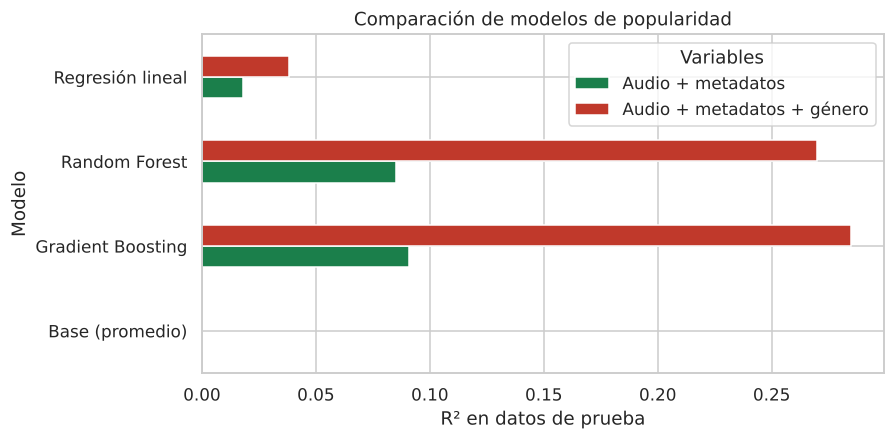

In [26]:
resultados_pop.pivot(index='Modelo', columns='Variables', values='R2').plot(kind='barh', figsize=(8, 4), color=['#1B7F4B', '#C0392B'])
plt.xlabel('R² en datos de prueba')
plt.title('Comparación de modelos de popularidad')
plt.show()

Al agregar el género el desempeño mejora mucho: el Gradient Boosting pasa de R² = 0.091 a **0.285** y el Random Forest de 0.085 a **0.270**; el MAE baja a 14.0 puntos (contra 18.8 del modelo base). La regresión lineal casi no mejora (0.018 a 0.038), porque la relación entre el género y la popularidad no es lineal y los modelos de árboles la aprovechan mejor.

Aun así, un R² de 0.285 significa que cerca del **71.5%** de la variación de la popularidad sigue sin explicarse.

## Variables más importantes
Importancia de cada variable en el Random Forest con género (la importancia de las 114 variables ficticias del género se suma en una sola barra).

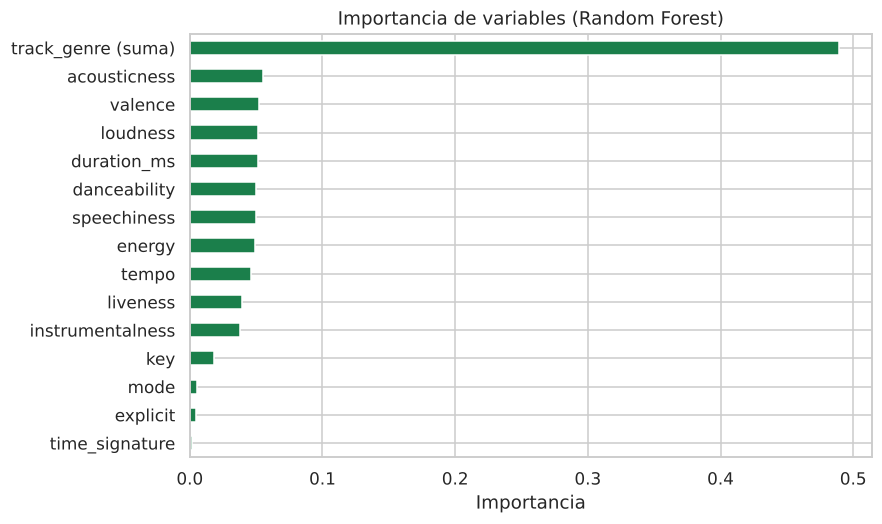

In [27]:
rf = modelos['Random Forest + género']
importancia = pd.Series(rf.feature_importances_, index=X_gen.columns)
resumen = importancia[variables].copy()
resumen['track_genre (suma)'] = importancia[generos.columns].sum()
resumen.sort_values().plot(kind='barh', figsize=(8, 5), color='#1B7F4B')
plt.xlabel('Importancia')
plt.title('Importancia de variables (Random Forest)')
plt.show()

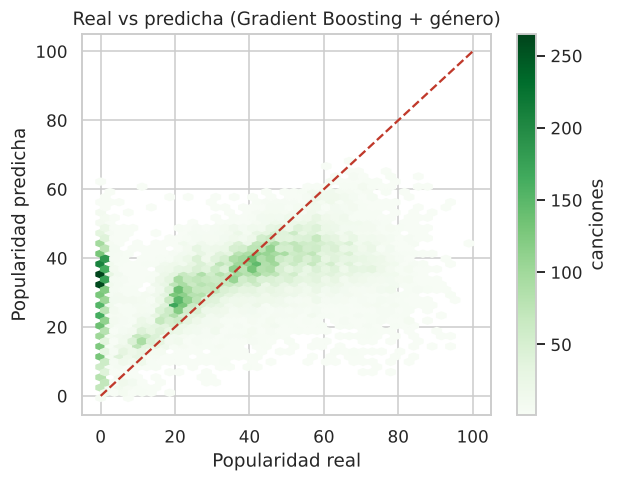

In [28]:
mejor = predicciones['Gradient Boosting']
plt.figure(figsize=(6, 4.5))
plt.hexbin(y_test, mejor, gridsize=40, cmap='Greens', mincnt=1)
plt.plot([0, 100], [0, 100], color='#C0392B', linestyle='--')
plt.xlabel('Popularidad real')
plt.ylabel('Popularidad predicha')
plt.title('Real vs predicha (Gradient Boosting + género)')
plt.colorbar(label='canciones')
plt.show()

- El Random Forest le da al **género** casi la mitad de la importancia total (≈ 0.49). Las variables de audio tienen importancias parecidas entre sí (≈ 0.04 a 0.055), con `acousticness`, `valence` y `loudness` arriba; `key`, `mode`, `explicit` y `time_signature` casi no aportan.
- En la gráfica de real contra predicha se ve que el modelo casi siempre predice entre 20 y 60 (se acerca al promedio) y no logra identificar ni las canciones con popularidad 0 (≈ 10% de las canciones) ni las muy populares (más de 70). Una posible explicación es que la popularidad depende de factores que no están en los datos, como la promoción, la fecha de lanzamiento y las reproducciones recientes.

# Análisis 3: Clasificación de género musical
**Tipo de análisis:** predictivo / supervisado (clasificación). **Objetivo:** predecir el género de una canción usando **únicamente** sus características acústicas.

Como una canción puede estar en varios géneros, aquí la etiqueta sería ambigua. Por eso solo se usan las canciones que aparecen **en un único género**. Se hacen dos experimentos: (A) los 114 géneros con Random Forest y (B) 10 géneros distintos entre sí comparando Random Forest contra SVM.

In [29]:
unicas = dataset[~dataset['track_id'].duplicated(keep=False)].reset_index(drop=True)
acusticas = ['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
print('Canciones con un solo género:', len(unicas))
unicas['track_genre'].value_counts().describe()[['min', 'mean', 'max']].round(0)

Canciones con un solo género: 72938


min      72.0
mean    651.0
max     999.0
Name: count, dtype: float64

## Experimento A: los 114 géneros (Random Forest)

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
ent, pru = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(unicas, groups=unicas['cancion']))
Xa_train, Xa_test = unicas.loc[ent, acusticas], unicas.loc[pru, acusticas]
ya_train, ya_test = unicas.loc[ent, 'track_genre'], unicas.loc[pru, 'track_genre']
rf_a = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=2, random_state=42).fit(Xa_train, ya_train)
pred_a = np.array(rf_a.predict(Xa_test), dtype=object)
top3 = np.argsort(rf_a.predict_proba(Xa_test), axis=1)[:, -3:]
clases = np.array(rf_a.classes_, dtype=object)
real_a = np.array(ya_test, dtype=object)
print('Géneros:', ya_train.nunique(), '| Acierto al azar:', round(1 / ya_train.nunique(), 4))
print('Accuracy:', round(accuracy_score(ya_test, pred_a), 3))
print('Accuracy top-3:', round((clases[top3] == real_a[:, None]).any(axis=1).mean(), 3))
print('F1 macro:', round(f1_score(ya_test, pred_a, average='macro'), 3))

Géneros: 112 | Acierto al azar: 0.0089
Accuracy: 0.269
Accuracy top-3: 0.45
F1 macro: 0.202


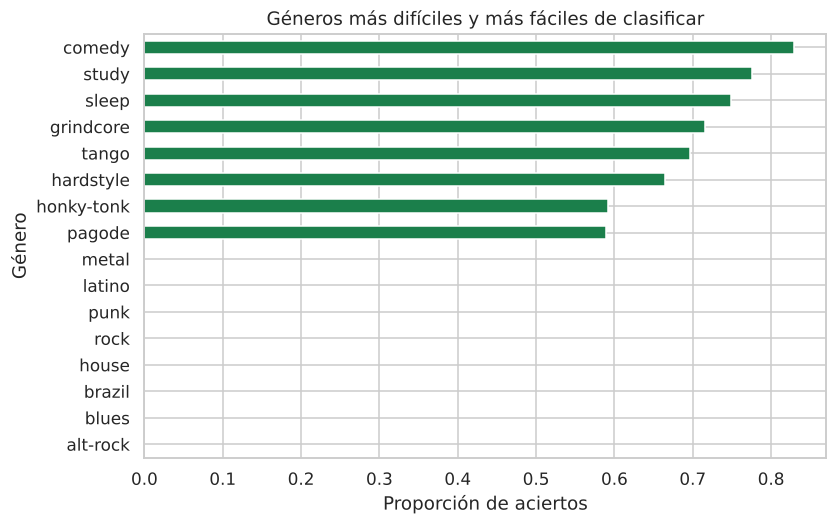

In [31]:
acierto = pd.Series(pred_a == real_a, index=real_a).groupby(level=0).mean().sort_values()
pd.concat([acierto.head(8), acierto.tail(8)]).plot(kind='barh', figsize=(8, 5), color='#1B7F4B')
plt.xlabel('Proporción de aciertos')
plt.ylabel('Género')
plt.title('Géneros más difíciles y más fáciles de clasificar')
plt.show()

Con **112 géneros** (*singer-songwriter* y *songwriter* se quedan sin canciones exclusivas porque todas sus canciones están también en otro género) el Random Forest logra una accuracy de **26.9%** (al azar sería 0.9%), una accuracy top-3 de **45.0%** (el género correcto está entre los 3 más probables en casi la mitad de los casos) y un F1 macro de 0.202.

Los géneros que más se reconocen por su sonido son *comedy* (≈ 83% de aciertos), *study* (≈ 78%), *sleep* (≈ 75%) y *grindcore* (≈ 71%). Los más difíciles (casi 0% de aciertos) son *metal*, *latino*, *punk*, *rock*, *house*, *brazil*, *blues* y *alt-rock*. Una posible explicación es que son géneros amplios que comparten sonido con otros géneros del conjunto (por ejemplo, *rock* con *alt-rock* o *hard-rock*).

## Experimento B: 10 géneros (Random Forest vs SVM)
Se eligen 10 géneros con estilos acústicos distintos y se quitan las canciones que aparecen en más de uno de esos 10 géneros, para que cada canción tenga una sola etiqueta; así los géneros quedan casi balanceados. Para SVM se estandarizan las variables (usa distancias) y se prueban combinaciones de `C` y `gamma` con validación cruzada de 3 pliegues.

In [32]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
elegidos = ['classical', 'country', 'hip-hop', 'heavy-metal', 'jazz', 'pop', 'reggae', 'rock', 'salsa', 'techno']
sub = dataset[dataset['track_genre'].isin(elegidos)]
sub = sub[~sub['track_id'].duplicated(keep=False)].reset_index(drop=True)
print(sub['track_genre'].value_counts().to_dict())
ent_b, pru_b = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(sub, groups=sub['cancion']))
Xb_train, Xb_test = sub.loc[ent_b, acusticas], sub.loc[pru_b, acusticas]
yb_train, yb_test = sub.loc[ent_b, 'track_genre'], sub.loc[pru_b, 'track_genre']
print('Canciones:', len(sub), '| Entrenamiento:', len(Xb_train), '| Prueba:', len(Xb_test))
rf_b = RandomForestClassifier(n_estimators=300, n_jobs=2, random_state=42).fit(Xb_train, yb_train)
busqueda = GridSearchCV(Pipeline([('escalar', StandardScaler()), ('svm', SVC())]), {'svm__C': [1, 10], 'svm__gamma': ['scale', 0.2]}, cv=3, n_jobs=2).fit(Xb_train, yb_train)
print('Mejores parámetros SVM:', busqueda.best_params_)
resultados_gen = pd.DataFrame({'Modelo': ['Random Forest', 'SVM (RBF)'],
                               'Accuracy': [accuracy_score(yb_test, rf_b.predict(Xb_test)), accuracy_score(yb_test, busqueda.predict(Xb_test))],
                               'F1 macro': [f1_score(yb_test, rf_b.predict(Xb_test), average='macro'), f1_score(yb_test, busqueda.predict(Xb_test), average='macro')]}).round(3)
resultados_gen

{'techno': 999, 'heavy-metal': 996, 'salsa': 991, 'jazz': 981, 'country': 961, 'rock': 952, 'classical': 855, 'reggae': 836, 'pop': 829, 'hip-hop': 764}
Canciones: 9164 | Entrenamiento: 7349 | Prueba: 1815
Mejores parámetros SVM: {'svm__C': 10, 'svm__gamma': 'scale'}


,Modelo,Accuracy,F1 macro
0,Random Forest,0.572,0.550
1,SVM (RBF),0.533,0.521


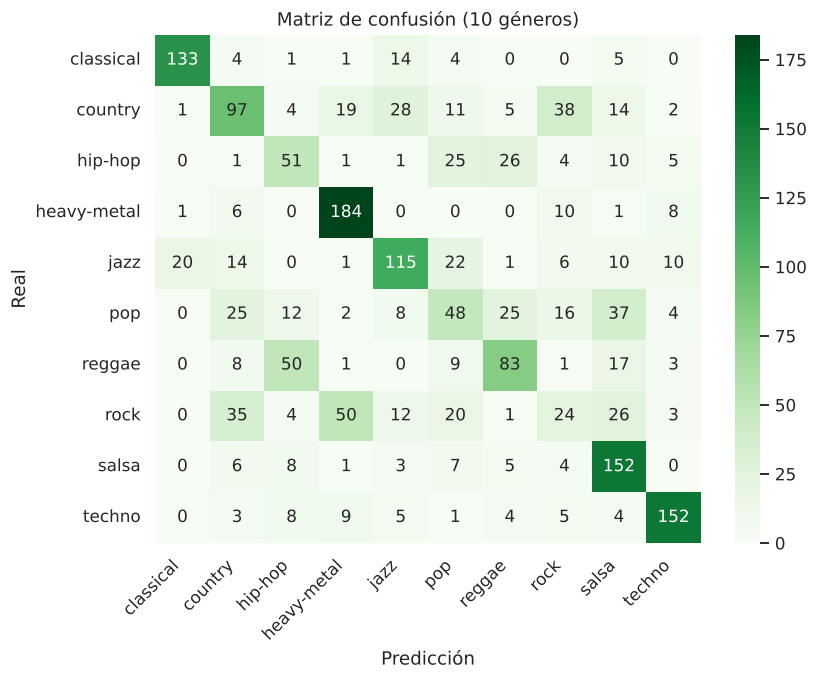

In [33]:
from sklearn.metrics import confusion_matrix, classification_report
mejor_b = busqueda if resultados_gen.loc[1, 'Accuracy'] >= resultados_gen.loc[0, 'Accuracy'] else rf_b
pred_b = mejor_b.predict(Xb_test)
cm = confusion_matrix(yb_test, pred_b, labels=elegidos)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=elegidos, yticklabels=elegidos)
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión (10 géneros)')
plt.xticks(rotation=45, ha='right')
plt.show()

In [34]:
print(classification_report(yb_test, pred_b, digits=2))

              precision    recall  f1-score   support

   classical       0.86      0.82      0.84       162
     country       0.49      0.44      0.46       219
 heavy-metal       0.68      0.88      0.77       210
     hip-hop       0.37      0.41      0.39       124
        jazz       0.62      0.58      0.60       199
         pop       0.33      0.27      0.30       177
      reggae       0.55      0.48      0.52       172
        rock       0.22      0.14      0.17       175
       salsa       0.55      0.82      0.66       186
      techno       0.81      0.80      0.80       191

    accuracy                           0.57      1815
   macro avg       0.55      0.56      0.55      1815
weighted avg       0.56      0.57      0.56      1815



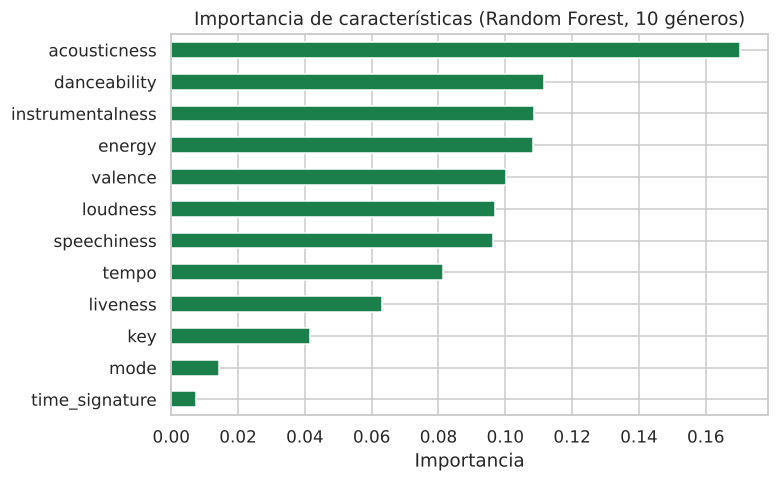

In [35]:
pd.Series(rf_b.feature_importances_, index=acusticas).sort_values().plot(kind='barh', figsize=(7, 4.5), color='#1B7F4B')
plt.xlabel('Importancia')
plt.title('Importancia de características (Random Forest, 10 géneros)')
plt.show()

- Con 10 géneros el **Random Forest** alcanza **57.2%** de accuracy (F1 macro 0.550) y el **SVM** 53.3% (F1 macro 0.521, con C = 10 y gamma = 'scale'). Ambos superan por mucho al azar (10%). Como el Random Forest fue mejor, la matriz de confusión y el reporte se hicieron con ese modelo.
- Los géneros más fáciles son *classical* (F1 = 0.84), *techno* (0.80) y *heavy-metal* (0.77). Los más difíciles son *rock* (0.17), *pop* (0.30) y *hip-hop* (0.39): por ejemplo, 50 de las 175 canciones de rock se clasificaron como heavy-metal y 35 como country, y 50 de las 172 de reggae como hip-hop.
- La característica más importante es `acousticness` (≈ 0.17), seguida de `danceability`, `instrumentalness` y `energy` (≈ 0.11 cada una); `mode` y `time_signature` casi no aportan.
- Con menos géneros y balanceados el desempeño sube de 26.9% (112 géneros) a 57.2%, pero sigue lejos de ser perfecto: **el sonido ayuda a reconocer el género, pero no basta**.

# Análisis 4: Reglas de asociación (Apriori)
**Tipo de análisis:** descriptivo / no supervisado. **Objetivo:** descubrir qué combinaciones de características acústicas aparecen con frecuencia en canciones **muy populares**.

Las reglas de asociación necesitan variables categóricas, así que primero se **discretizan** las características continuas en niveles *baja / media / alta* (terciles, cada uno con un tercio de las canciones). La popularidad se divide en **alta** (el 25% más popular) y **baja** (el 25% menos popular). Se usan las canciones distintas (`canciones`) como si cada una fuera una transacción.

In [36]:
discretas = pd.DataFrame(index=canciones.index)
for col in ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'liveness', 'valence', 'tempo']:
    discretas[col] = pd.qcut(canciones[col].rank(method='first'), 3, labels=['baja', 'media', 'alta'])
discretas['instrumentalness'] = pd.cut(canciones['instrumentalness'], [-0.01, 0.01, 0.5, 1.0], labels=['vocal', 'mixta', 'instrumental'])
discretas['explicit'] = np.where(canciones['explicit'] == 1, 'si', 'no')
q1, q3 = canciones['popularity'].quantile([0.25, 0.75])
discretas['popularidad'] = np.select([canciones['popularity'] >= q3, canciones['popularity'] <= q1], ['alta', 'baja'], 'media')
print('Popularidad alta: >=', q3, '| baja: <=', q1)
transacciones = pd.get_dummies(discretas).astype(bool).drop(columns=['popularidad_media', 'explicit_no'])
print(transacciones.shape)
transacciones.mean().round(3).sort_values(ascending=False).head(12)

Popularidad alta: >= 49.0 | baja: <= 19.0
(89578, 30)


instrumentalness_vocal    0.683
danceability_baja         0.333
danceability_alta         0.333
energy_baja               0.333
energy_media              0.333
danceability_media        0.333
loudness_baja             0.333
loudness_media            0.333
loudness_alta             0.333
speechiness_baja          0.333
speechiness_media         0.333
speechiness_alta          0.333
dtype: float64

## Algoritmo Apriori
Como la librería `mlxtend` no estaba instalada, se programa el algoritmo **Apriori** directamente: se buscan los *itemsets* frecuentes nivel por nivel (de 1 a 4 elementos) y solo se combinan los itemsets que ya eran frecuentes (propiedad de Apriori). El conteo se hace con operaciones de bits para que sea rápido.

In [37]:
def apriori_propio(matriz, min_support, max_len):
    n = len(matriz)
    bits = {c: int.from_bytes(np.packbits(matriz[c].values).tobytes(), 'big') for c in matriz.columns}
    nivel = {}
    for c in matriz.columns:
        s = bits[c].bit_count() / n
        if s >= min_support:
            nivel[(c,)] = (bits[c], s)
    frecuentes = {k: v[1] for k, v in nivel.items()}
    longitud = 1
    while nivel and longitud < max_len:
        longitud += 1
        claves = sorted(nivel)
        nuevos = {}
        for i in range(len(claves)):
            for j in range(i + 1, len(claves)):
                a, b = claves[i], claves[j]
                if a[:-1] != b[:-1]:
                    break
                cand = a + (b[-1],)
                if all(cand[:m] + cand[m + 1:] in nivel for m in range(len(cand) - 1)):
                    mascara = nivel[a][0] & bits[b[-1]]
                    s = mascara.bit_count() / n
                    if s >= min_support:
                        nuevos[cand] = (mascara, s)
        nivel = nuevos
        frecuentes.update({k: v[1] for k, v in nivel.items()})
    return frecuentes
inicio = time.time()
frecuentes = apriori_propio(transacciones, min_support=0.02, max_len=4)
print('Itemsets frecuentes:', len(frecuentes), '| segundos:', round(time.time() - inicio, 1))

Itemsets frecuentes: 4778 | segundos: 0.0


## Generar las reglas
Para cada itemset que contiene a la popularidad se calcula: **support** (fracción de canciones con todos los elementos), **confidence** (de las canciones con el antecedente, cuántas tienen ese nivel de popularidad) y **lift** (cuánto mejora respecto a la popularidad base; mayor a 1 indica asociación positiva).

In [38]:
def reglas_para(consecuente, min_conf=0.0, min_lift=1.0):
    filas = []
    for itemset, sop in frecuentes.items():
        if consecuente in itemset and len(itemset) > 1:
            antecedente = tuple(x for x in itemset if x != consecuente)
            conf = sop / frecuentes[antecedente]
            lift = conf / frecuentes[(consecuente,)]
            if conf >= min_conf and lift >= min_lift:
                filas.append((' + '.join(antecedente), len(antecedente), sop, round(sop * len(canciones)), conf, lift))
    return pd.DataFrame(filas, columns=['Antecedente', 'Elementos', 'Support', 'Canciones', 'Confidence', 'Lift']).sort_values('Lift', ascending=False).reset_index(drop=True)
reglas_alta = reglas_para('popularidad_alta')
reglas_baja = reglas_para('popularidad_baja')
print('Reglas hacia popularidad alta (lift > 1):', len(reglas_alta), '| hacia popularidad baja:', len(reglas_baja))
print('Popularidad alta base:', round(frecuentes[('popularidad_alta',)], 3), '| baja base:', round(frecuentes[('popularidad_baja',)], 3))

Reglas hacia popularidad alta (lift > 1): 281 | hacia popularidad baja: 226
Popularidad alta base: 0.251 | baja base: 0.257


In [39]:
reglas_alta.head(10).round(3)

,Antecedente,Elementos,Support,Canciones,Confidence,Lift
0,explicit_si + instrumentalness_vocal,2,0.025,2270,0.350,1.393
1,instrumentalness_vocal + liveness_media + vale...,3,0.022,1935,0.346,1.377
2,energy_media + instrumentalness_vocal + loudne...,3,0.031,2755,0.342,1.361
3,danceability_alta + instrumentalness_vocal + v...,3,0.025,2266,0.340,1.353
4,acousticness_baja + energy_media + instrumenta...,3,0.020,1823,0.338,1.346
5,energy_media + loudness_alta,2,0.033,2979,0.337,1.342
6,explicit_si,1,0.029,2595,0.337,1.341
7,energy_media + instrumentalness_vocal + livene...,3,0.028,2542,0.329,1.309
8,instrumentalness_vocal + liveness_media + loud...,3,0.025,2247,0.328,1.306
9,acousticness_media + instrumentalness_vocal + ...,3,0.030,2705,0.327,1.301


In [40]:
reglas_baja.head(10).round(3)

,Antecedente,Elementos,Support,Canciones,Confidence,Lift
0,instrumentalness_instrumental + speechiness_alta,2,0.024,2161,0.490,1.907
1,acousticness_baja + energy_alta + instrumental...,3,0.024,2112,0.480,1.866
2,acousticness_baja + instrumentalness_instrumental,2,0.037,3325,0.477,1.856
3,energy_alta + instrumentalness_instrumental,2,0.028,2474,0.464,1.803
4,acousticness_baja + danceability_alta + livene...,3,0.021,1855,0.452,1.759
5,acousticness_baja + danceability_alta + tempo_...,3,0.025,2264,0.439,1.707
6,danceability_alta + instrumentalness_instrumental,2,0.024,2190,0.438,1.702
7,instrumentalness_instrumental + tempo_media,2,0.030,2682,0.425,1.652
8,acousticness_baja + danceability_alta,2,0.040,3551,0.409,1.589
9,instrumentalness_instrumental + liveness_baja,2,0.029,2590,0.392,1.524


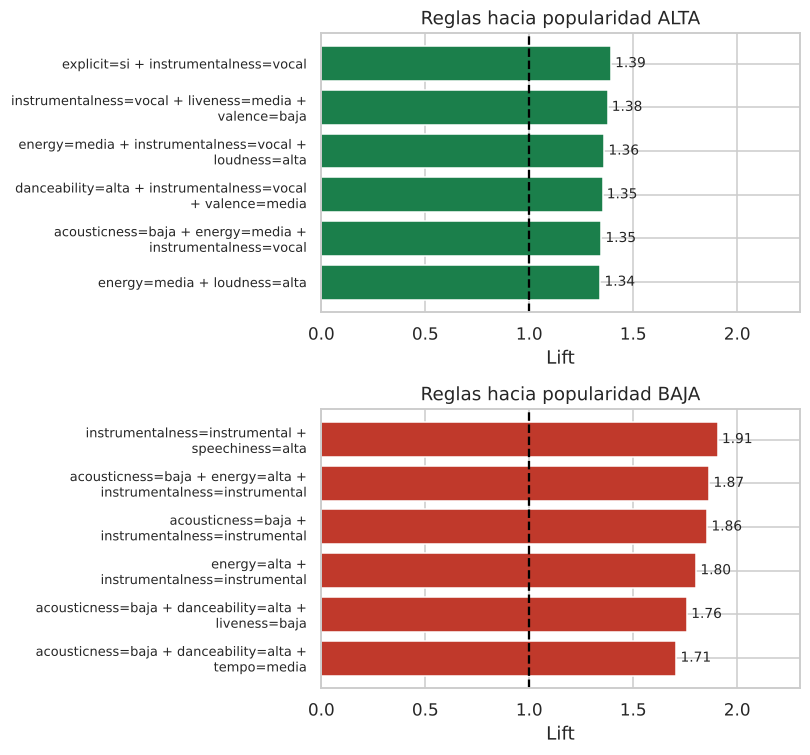

In [41]:
import textwrap
fig, ejes = plt.subplots(2, 1, figsize=(7.5, 7))
for eje, tabla, titulo, color in [(ejes[0], reglas_alta.head(6), 'Reglas hacia popularidad ALTA', '#1B7F4B'), (ejes[1], reglas_baja.head(6), 'Reglas hacia popularidad BAJA', '#C0392B')]:
    tabla = tabla.iloc[::-1]
    etiquetas = ['\n'.join(textwrap.wrap(a.replace('_', '='), 42)) for a in tabla['Antecedente']]
    eje.barh(etiquetas, tabla['Lift'], color=color)
    eje.axvline(1, color='black', linestyle='--')
    for i, v in enumerate(tabla['Lift']):
        eje.text(v + 0.02, i, f'{v:.2f}', va='center', fontsize=9)
    eje.set_xlim(0, 2.3)
    eje.set_title(titulo)
    eje.set_xlabel('Lift')
    eje.tick_params(axis='y', labelsize=8.5)
plt.tight_layout()
plt.show()

- Con `min_support = 0.02` se encontraron **4,778 itemsets frecuentes**, de los que salieron **281 reglas** hacia popularidad alta y **226** hacia popularidad baja (con lift mayor a 1). La popularidad alta aparece en el 25.1% de las canciones y la baja en el 25.7%.
- **Hacia popularidad ALTA las asociaciones son débiles:** el mayor lift es **1.39** (`explicit_si + instrumentalness_vocal`: 35.0% de confianza contra 25.1% base, 2,270 canciones). También aparecen `energy_media + loudness_alta` (confianza 33.7%, lift 1.34) y `explicit_si` solo (lift 1.34). Los rasgos que se repiten son **tener voz** (no ser instrumental), letra explícita, energía media y volumen alto.
- **Hacia popularidad BAJA las asociaciones son más fuertes:** `instrumentalness_instrumental + speechiness_alta` tiene lift **1.91** (49.0% de confianza: casi la mitad de las canciones con ese perfil están en el 25% menos popular) y `acousticness_baja + instrumentalness_instrumental` tiene lift 1.86 (47.7%, 3,325 canciones).
- **Interpretación:** lo que más se asocia con ser popular es tener voz, y lo que más se asocia con ser poco popular es ser instrumental. Pero ninguna regla llega a un lift de 2, así que **no existe una 'receta acústica' del éxito**; esto coincide con el R² bajo del análisis 2.

# Interpretación general
- **Análisis 1 (K-Means + PCA):** las canciones se agrupan en 5 segmentos con sentido musical (*Hablado*, *Bailable y alegre*, *Suave y acústico*, *Intenso y oscuro* e *Instrumental y ambiental*). La silueta es baja (0.18), por lo que los grupos se traslapan, pero sirven para construir un recomendador por similitud dentro de cada segmento.
- **Análisis 2 (popularidad):** con audio y metadatos el R² máximo es 0.091; agregando el género sube a **0.285** (Gradient Boosting, MAE = 13.95). La popularidad depende en gran parte de factores que no están en el audio.
- **Análisis 3 (género):** 26.9% de accuracy con 112 géneros (45.0% top-3) y 57.2% con 10 géneros (Random Forest). El sonido ayuda, pero no distingue bien géneros cercanos.
- **Análisis 4 (Apriori):** las reglas hacia popularidad alta son débiles (lift máximo 1.39) y las de popularidad baja son algo más fuertes (lift máximo 1.91, canciones instrumentales).
- **Idea común:** los datos de audio describen bien *cómo suena* una canción, pero explican poco *qué tan popular es*. Para predecir popularidad harían falta datos como artista, fecha de lanzamiento, promoción o comportamiento de los usuarios.